# Упражнения по регуляризации и методу градиентного спуска

## Вопрос 1: Генерация нелинейных данных с гетероскедастичным шумом

В реальных задачах шум в данных часто зависит от значения входных признаков (гетероскедастичность).

* Сгенерируйте 250 равномерно распределенных точек $x$ на отрезке $[0, 5]$.
* Вычислите истинное значение целевой переменной по формуле: $y_{\\text{true}} = 2.5 \\cdot \\sin(1.5 x) + 0.3 x^2 - 1.5$.

* Добавьте гауссов шум, дисперсия которого растет линейно с ростом $x$: $\\sigma(x) = 0.15 \\cdot (1 + 0.8x)$.

* Разделите данные на обучающую (70%) и тестовую (30%) выборки с фиксированным `random_state=42`.
* Постройте график тренировочных, тестовых точек и истинной функции.

(175, 1) (75, 1)


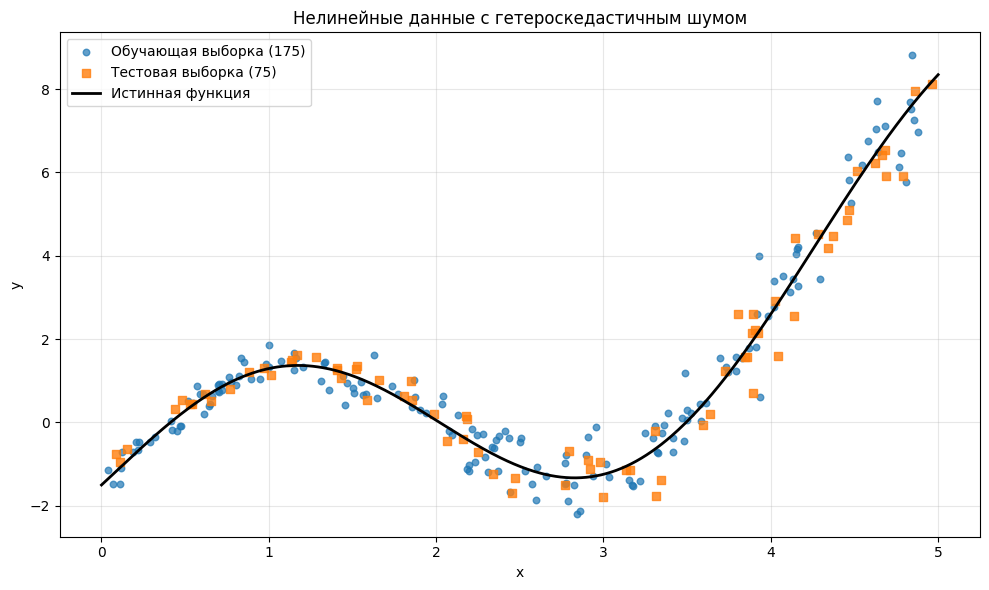

In [44]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from scipy.stats import skew
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.model_selection import learning_curve, KFold, GridSearchCV
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.linear_model import LinearRegression, Ridge, ElasticNet, LassoCV, lasso_path, SGDRegressor, RidgeCV

rng = np.random.default_rng(42)
n = 250

x = rng.uniform(0, 5, n)

y_true = 2.5 * np.sin(1.5 * x) + 0.3 * x**2 - 1.5

sigma = 0.15 * (1 + 0.8 * x)
y = y_true + rng.normal(0, sigma)

X = x.reshape(-1, 1)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)
print(X_train.shape, X_test.shape) 

xs = np.linspace(0, 5, 500)
ys = 2.5 * np.sin(1.5 * xs) + 0.3 * xs**2 - 1.5

plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, s=22, alpha=0.7, label="Обучающая выборка (175)")
plt.scatter(X_test, y_test, s=26, alpha=0.8, marker="s", label="Тестовая выборка (75)")
plt.plot(xs, ys, "k-", lw=2, label="Истинная функция")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Нелинейные данные с гетероскедастичным шумом")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Вопрос 2: Исследование полиномов высокой степени и феномена Рунге

При слишком высокой степени полинома модель стремится идеально пройти через все точки обучающей выборки, образуя сильные осцилляции на краях интервала.

* Сформируйте полиномиальные признаки 25-й степени (`degree=25`).

* Обучите обычную линейную регрессию (`LinearRegression`) без регуляризации.

* Оцените $RMSE$ на обучающей и тестовой выборках.

Постройте график предсказаний модели на всем отрезке $[0, 5]$. Проанализируйте осцилляции модели на границах интервала.

RMSE train: 0.6428702112936342
RMSE test : 1.258370522973793


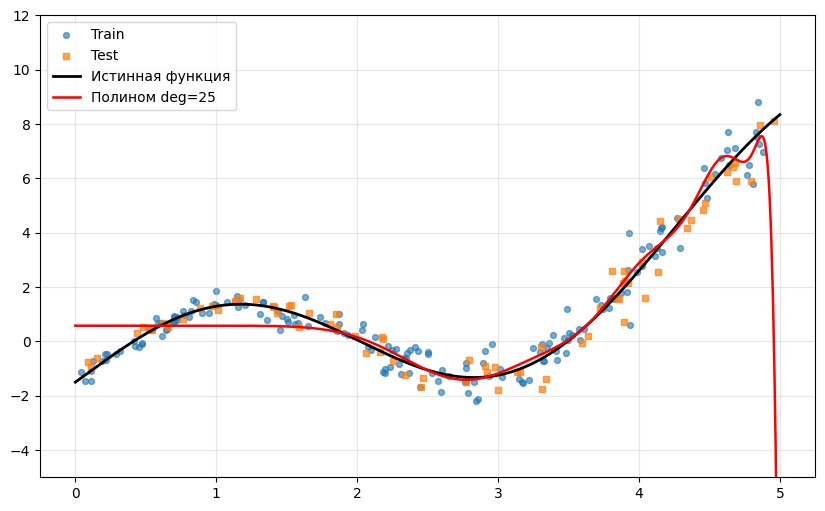

In [45]:
poly = PolynomialFeatures(degree=25, include_bias=False)
Xtr = poly.fit_transform(X_train)
Xte = poly.transform(X_test)

model = LinearRegression().fit(Xtr, y_train)

rmse = lambda a, b: np.sqrt(mean_squared_error(a, b))
print("RMSE train:", rmse(y_train, model.predict(Xtr)))
print("RMSE test :", rmse(y_test, model.predict(Xte)))

xs = np.linspace(0, 5, 1000).reshape(-1, 1)
yp = model.predict(poly.transform(xs))

plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, s=18, alpha=0.6, label="Train")
plt.scatter(X_test, y_test, s=22, marker="s", alpha=0.7, label="Test")
plt.plot(xs, 2.5*np.sin(1.5*xs) + 0.3*xs**2 - 1.5, "k-", lw=2, label="Истинная функция")
plt.plot(xs, yp, "r-", lw=1.8, label="Полином deg=25")
plt.ylim(-5, 12)
plt.legend(); plt.grid(alpha=0.3); plt.show()

## Вопрос 3: Диагностика Bias-Variance с помощью кривых обучения (Learning Curves)

Кривые обучения позволяют определить, принесет ли пользу добавление новых данных или необходима регуляризация.\

* Напишите функцию для расчета и построения кривых обучения с помощью `learning_curve` из `sklearn.model_selection`.

* Постройте кривые обучения для неуправляемой линейной регрессии (степень 15) и Ridge-регрессии (степень 15, $\\alpha = 1.0$).

* Объясните разрыв (*generalization gap*) между ошибкой на обучении и валидации для обеих моделей."

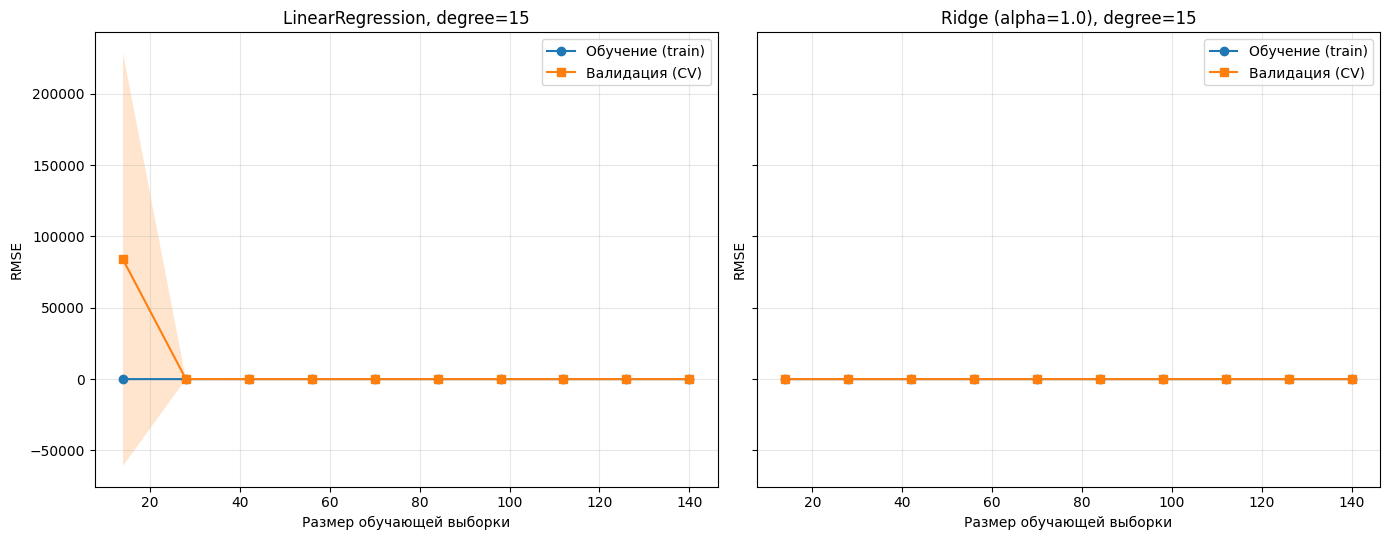

In [46]:
def plot_learning_curve(model, X, y, title, ax):
    cv = KFold(n_splits=5, shuffle=True, random_state=42)
    sizes, tr, va = learning_curve(
        model, X, y, cv=cv, train_sizes=np.linspace(0.1, 1.0, 10),
        scoring="neg_root_mean_squared_error", n_jobs=-1)
    tr, va = -tr, -va
    trm, vam = tr.mean(1), va.mean(1)
    ax.plot(sizes, trm, "o-", label="Обучение (train)")
    ax.fill_between(sizes, trm - tr.std(1), trm + tr.std(1), alpha=0.2)
    ax.plot(sizes, vam, "s-", label="Валидация (CV)")
    ax.fill_between(sizes, vam - va.std(1), vam + va.std(1), alpha=0.2)
    ax.set_title(title)
    ax.set_xlabel("Размер обучающей выборки")
    ax.set_ylabel("RMSE")
    ax.grid(alpha=0.3)
    ax.legend()
    return sizes, trm, vam

lin = make_pipeline(PolynomialFeatures(15, include_bias=False),
                    StandardScaler(), LinearRegression())
rdg = make_pipeline(PolynomialFeatures(15, include_bias=False),
                    StandardScaler(), Ridge(alpha=1.0))

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
plot_learning_curve(lin, X_train, y_train, "LinearRegression, degree=15", ax[0])
plot_learning_curve(rdg, X_train, y_train, "Ridge (alpha=1.0), degree=15", ax[1])
plt.tight_layout()
plt.show()

## Вопрос 4: Подготовка продвинутых признаков и обработка Ames Housing

Перейдем к реальному набору данных о продажах недвижимости `Ames_Housing_Sales.csv`.

* Загрузите датасет, выполните One-Hot Encoding категориальных признаков.

* Проверьте признаки на асимметрию (`skew > 0.75`) и примените преобразование `np.log1p`.

* Создайте парные взаимодействия признаков только для ключевых числовых переменных (`LotArea`, `GrLivArea`, `TotalBsmtSF`), используя `PolynomialFeatures(interaction_only=True)`.\

Разделите данные на обучающую и тестовую выборки (70/30).

In [47]:
df = pd.read_csv("./data/Ames_Housing_Sales.csv")
target = "SalePrice"
y = df[target]
X = df.drop(columns=[target] + [c for c in ["Id"] if c in df.columns])

num_cols = X.select_dtypes(include="number").columns
cat_cols = X.select_dtypes(exclude="number").columns

X[num_cols] = X[num_cols].fillna(X[num_cols].median())
X[cat_cols] = X[cat_cols].fillna("None")

X = pd.get_dummies(X, columns=list(cat_cols), drop_first=True)

skewness = X[num_cols].apply(lambda s: skew(s))
skewed = skewness[(skewness > 0.75) & (X[num_cols].min() > -1)].index
print(f"Признаков с skew > 0.75: {len(skewed)}")
X[skewed] = np.log1p(X[skewed])

key = ["LotArea", "GrLivArea", "TotalBsmtSF"]
poly = PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)
inter = poly.fit_transform(X[key])
names = poly.get_feature_names_out(key)

inter_df = pd.DataFrame(inter, columns=names, index=X.index)
inter_df = inter_df[[c for c in names if " " in c]]
X = pd.concat([X, inter_df], axis=1)
print(X.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)
print(X_train.shape, X_test.shape)

Признаков с skew > 0.75: 23
(1379, 254)
(965, 254) (414, 254)


## Вопрос 5: Двумерный сетчатый поиск гиперпараметров ElasticNet с GridSearchCV

Регрессия `ElasticNet` комбинирует $L_1$ и $L_2$ штрафы через два ключевых гиперпараметра: $\\alpha$ (сила регуляризации) и `l1_ratio` (доля $L_1$-штрафа).

* Настройте сетку параметров: `alpha`: `[1e-4, 1e-3, 0.01, 0.1, 1.0, 10.0]`, `l1_ratio`: `[0.1, 0.3, 0.5, 0.7, 0.9]`.

* Запустите `GridSearchCV` с 5-кратной кросс-валидацией (`cv=5`) и метрикой `neg_root_mean_squared_error`.

* Визуализируйте результаты сетчатого поиска в виде тепловой карты (`sns.heatmap`).

* Выведите оптимальные параметры и оцените итоговое $RMSE$ на тестовой выборке."

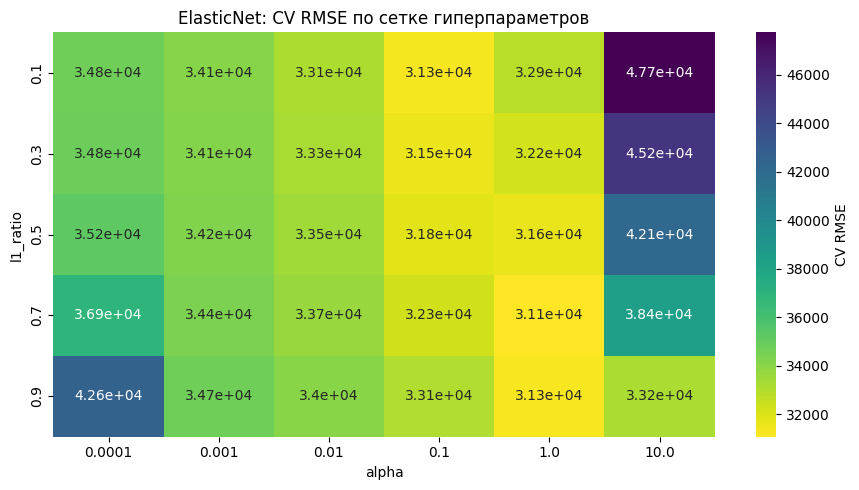

Лучшие параметры: {'enet__alpha': 1.0, 'enet__l1_ratio': 0.7}
CV RMSE: 31082.609694307037
Test RMSE: 36941.91378560333


In [48]:
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("enet", ElasticNet(max_iter=20000, random_state=42)),
])

param_grid = {
    "enet__alpha": [1e-4, 1e-3, 0.01, 0.1, 1.0, 10.0],
    "enet__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9],
}

gs = GridSearchCV(
    pipe, param_grid, cv=5,
    scoring="neg_root_mean_squared_error", n_jobs=-1,
)
gs.fit(X_train, y_train)

res = pd.DataFrame(gs.cv_results_)
res["RMSE"] = -res["mean_test_score"]
heat = res.pivot(index="param_enet__l1_ratio",
                 columns="param_enet__alpha", values="RMSE").astype(float)

plt.figure(figsize=(9, 5))
sns.heatmap(heat, annot=True, fmt=".3g", cmap="viridis_r",
            cbar_kws={"label": "CV RMSE"})
plt.xlabel("alpha")
plt.ylabel("l1_ratio")
plt.title("ElasticNet: CV RMSE по сетке гиперпараметров")
plt.tight_layout()
plt.show()

print("Лучшие параметры:", gs.best_params_)
print("CV RMSE:", -gs.best_score_)
test_rmse = np.sqrt(mean_squared_error(y_test, gs.predict(X_test)))
print("Test RMSE:", test_rmse)

## Вопрос 6: Анализ разряженности (Sparsity) моделей Lasso и отбор признаков

$L_1$-регуляризация способна занулять коэффициенты неинформативных признаков.

* Обучите модель `LassoCV` с диапазоном `alphas = np.logspace(-4, 1, 50)`.

* Постройте график зависимости количества ненулевых коэффициентов от значения $\\alpha$.
* Выделите ТОП-10 наиболее важных признаков с наибольшими абсолютными значениями коэффициентов при оптимальном $\\alpha$.
* Какая доля признаков была полностью исключена из модели?

Оптимальный alpha: 0.002682695795279727


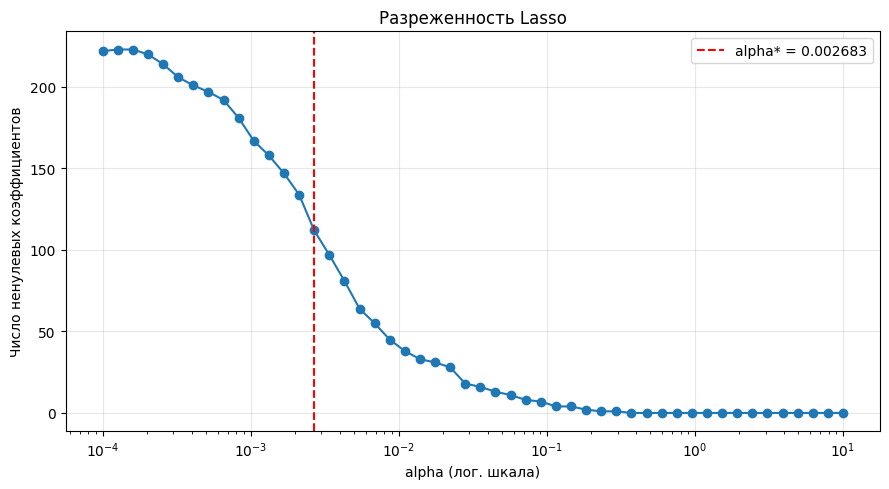

GrLivArea                0.086878
OverallQual              0.080214
LotArea GrLivArea        0.061455
YearBuilt                0.056949
PoolQC_Gd               -0.047828
OverallCond              0.041850
1stFlrSF                 0.029610
BsmtFinSF1               0.029068
SaleCondition_Partial    0.025982
GarageCars               0.023862
dtype: float64
Исключено: 142 из 254 (55.9%)


In [49]:
feature_names = X_train.columns

scaler = StandardScaler().fit(X_train)
Xs = scaler.transform(X_train)
y_log = np.log1p(y_train)

alphas = np.logspace(-4, 1, 50)

lcv = LassoCV(alphas=alphas, cv=5, max_iter=50000, random_state=42)
lcv.fit(Xs, y_log)
print("Оптимальный alpha:", lcv.alpha_)

a, coefs, _ = lasso_path(Xs, y_log, alphas=alphas, max_iter=50000)
nnz = (coefs != 0).sum(axis=0)

plt.figure(figsize=(9, 5))
plt.semilogx(a, nnz, "o-")
plt.axvline(lcv.alpha_, color="r", ls="--", label=f"alpha* = {lcv.alpha_:.4g}")
plt.xlabel("alpha (лог. шкала)")
plt.ylabel("Число ненулевых коэффициентов")
plt.title("Разреженность Lasso")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

coef = pd.Series(lcv.coef_, index=feature_names)
top10 = coef.reindex(coef.abs().sort_values(ascending=False).index).head(10)
print(top10)

n_zero = (coef == 0).sum()
print(f"Исключено: {n_zero} из {len(coef)} ({n_zero / len(coef):.1%})")

## Вопрос 7: Настройка схем скорости обучения (Learning Rate Schedules) в SGDRegressor

Алгоритм стохастического градиентного спуска критически чувствителен к масштабу данных и выбору правила изменения шага $\\eta$.

* Отсштабируйте признаки `X_train_ames` и `X_test_ames` с помощью `StandardScaler`.

Обучите четыре версии `SGDRegressor` с регуляризацией `penalty='elasticnet'`, используя различные стратегии `learning_rate`:

1. `'constant'` (`eta0=0.01`)

2. `'optimal'`

3. `'invscaling'` (`eta0=0.01`, `power_t=0.25`)

4. `'adaptive'` (`eta0=0.01`)

* Сравните полученные значения $RMSE$ и общее число итераций до сходимости (`n_iter_`).

In [50]:
scaler = StandardScaler().fit(X_train)
X_tr = scaler.transform(X_train)
X_te = scaler.transform(X_test)


y_tr = np.log1p(y_train)
y_te = np.log1p(y_test)


schedules = {
    "constant":   dict(learning_rate="constant", eta0=0.01),
    "optimal":    dict(learning_rate="optimal"),
    "invscaling": dict(learning_rate="invscaling", eta0=0.01, power_t=0.25),
    "adaptive":   dict(learning_rate="adaptive", eta0=0.01),
}

rows = []
for name, kw in schedules.items():
    model = SGDRegressor(
        penalty="elasticnet", alpha=1e-4, l1_ratio=0.5,
        max_iter=1000, tol=1e-3, random_state=42, **kw,
    ).fit(X_tr, y_tr)
    pred = model.predict(X_te)
    rows.append({
        "learning_rate": name,
        "RMSE (test, log)": np.sqrt(mean_squared_error(y_te, pred)),
        "n_iter_": model.n_iter_,
    })

results = pd.DataFrame(rows).set_index("learning_rate")
print(results)

               RMSE (test, log)  n_iter_
learning_rate                           
constant           1.624794e+12        6
optimal            2.892555e+13       81
invscaling         1.361080e+01        6
adaptive           7.497503e+10       36


## Вопрос 8: Сравнительный анализ устойчивости моделей к выбросам (Outliers)

Среднеквадратичная ошибка ($MSE$) в оптимизации градиентным спуском квадратично штрафует отклонения, делая модели чувствительными к аномалиям.

* Добавьте в 5% случайных точек обучающей выборки `y_train_ames` аномальные выбросы (увеличьте их значение в 3 раза).

* Обучите следующие модели на искаженных данных:

1. OLS (`LinearRegression`)
2. Ridge (`RidgeCV`)     
3. SGDRegressor с функциями потерь `loss='squared_error'` ($L_2$) и `loss='huber'` (Huber loss, комбинирующий $L_1$ и $L_2$).

* Оцените $RMSE$ и $MAE$ каждой модели на чистой тестовой выборке `y_test_ames`.

     

In [51]:
rng = np.random.default_rng(42)
y_bad = np.asarray(y_train, dtype=float).copy()     
idx = rng.choice(len(y_bad), size=int(0.05 * len(y_bad)), replace=False)
y_bad[idx] *= 3

y_tr_bad = np.log1p(y_bad)
y_tr_clean = np.log1p(np.asarray(y_train, dtype=float))
y_te = np.log1p(np.asarray(y_test, dtype=float))        

scaler = StandardScaler().fit(X_train)
X_tr = scaler.transform(X_train)
X_te = scaler.transform(X_test)

def make_models():
    return {
        "OLS": LinearRegression(),
        "RidgeCV": RidgeCV(alphas=np.logspace(-3, 3, 13)),
        "SGD (L2)": SGDRegressor(loss="squared_error", max_iter=1000, tol=1e-3, random_state=42),
        "SGD (Huber)": SGDRegressor(loss="huber", epsilon=0.1, max_iter=1000, tol=1e-3, random_state=42),
    }

def evaluate(y_fit):
    rows = []
    for name, model in make_models().items():
        model.fit(X_tr, y_fit)
        pred = model.predict(X_te)
        rows.append({"model": name,
                     "RMSE": np.sqrt(mean_squared_error(y_te, pred)),
                     "MAE": mean_absolute_error(y_te, pred)})
    return pd.DataFrame(rows).set_index("model")

print("Обучение на искажённых данных:")
print(evaluate(y_tr_bad).round(4))
print("\nДля сравнения, обучение на чистых данных:")
print(evaluate(y_tr_clean).round(4))

Обучение на искажённых данных:
                RMSE     MAE
model                       
OLS           0.2278  0.1542
RidgeCV       0.1748  0.1168
SGD (L2)     13.5898  7.5066
SGD (Huber)   0.1771  0.0988

Для сравнения, обучение на чистых данных:
                RMSE     MAE
model                       
OLS           0.1679  0.0994
RidgeCV       0.1777  0.0980
SGD (L2)     13.6347  7.5192
SGD (Huber)   0.1728  0.0975
